[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/14_IoT_IIoT_Attack_Detection/RHQCNN_IntrusionDetection_Mazroa2026.ipynb)

# RHQ-CNN for Edge-IIoT intrusion detection: Mazroa et al. (2026) step by step

**Paper.** Alanoud Al Mazroa, Abdulrahman Mohammed Alamoudi, Nurdaulet Karabayev, Jawad Ahmad and Muhammad Shahbaz Khan, *"Quantum-Enhanced Security for Edge-IIoT: Robust Intrusion Detection with a Novel Quantum-Classical Neural Network"*, Computers, Materials & Continua (Tech Science Press) 89(1):55, 2026. DOI: [10.32604/cmc.2026.083381](https://doi.org/10.32604/cmc.2026.083381).

**What this notebook does.** It rebuilds the paper's **Residual Hybrid Quantum-Classical Neural Network (RHQ-CNN)** for the 15-class Edge-IIoTset task: a classical encoder (58 -> 128 -> 32 -> 4) squeezes a network-traffic record into four angles, a **4-qubit variational circuit with serial data re-uploading** (PennyLane) transforms them, and a **residual skip connection** concatenates the quantum features with the classical latent vector before a small softmax head. It then re-runs the paper's controlled **ablation** (Table 6), the **deployment-cost** comparison with XGBoost and a 1D-CNN (Table 7), the **bootstrap confidence intervals** (Table 8) and the per-class report (Table 5), and finishes with a side-by-side comparison against the paper's numbers.

**How to run.** Open in Colab (CPU runtime is enough) and choose *Runtime -> Run all*. `FAST_MODE = True` (a class-capped subset, 4 epochs, one seed) takes about 7 minutes; `FAST_MODE = False` uses all cleaned rows, 10 epochs and three seeds and took about 70 minutes on a shared 8-core CPU (committed outputs are from this full run). Data are downloaded from Hugging Face inside the notebook, no key is needed.

**What you get at the end.** The data and the circuit drawn from the real objects, the paper's four ablation variants trained here, a table that puts the paper's numbers next to ours with a verdict for each claim, and a critical reading.

> **Data note (important).** The paper uses the full *DNN/ML-ready* Edge-IIoTset table (2,219,201 records, 72 % Normal). That 2.2 M-row file is only on Kaggle / IEEE DataPort (login needed). The only public no-login copy is the **157,800-row "ML-EdgeIIoT-dataset" table** (Hugging Face `Sunayanajagadesh/ML_EdgeIIoT_dataset`) from the same testbed with the **same 63 columns, the same 15 classes and the same 58 usable features**. Its three smallest classes are complete (Ransomware, Fingerprinting and MITM have exactly the paper's *original* counts), but the big classes (Normal, DDoS, ...) are down-sampled, so the class mix is far more balanced than in the paper. All numbers below are therefore *not* on the paper's exact data and are not expected to match it to the last digit.

## The paper in one page

**Problem.** Intrusion detection for Edge-IIoT traffic (15 classes: Normal plus 14 attacks) on resource-limited gateways, with a model that is small, stable to train, and uses a quantum circuit in the *decision* path rather than only as a feature map.

**Decision.** Multi-class classification of one network record at a time (Zeek/TShark packet features), softmax over 15 classes.

**Method (Section 3).**
1. *Preprocessing.* Drop `frame.time`, `ip.src_host`, `ip.dst_host`; drop rows with missing values; drop duplicates (keep first); label-encode the classes; 80:20 stratified train/test split, then 20 % of the training part as validation; min-max scale every feature to [0, pi] (Eq. 1). D = 58 features.
2. *Classical encoder (Eq. 2-3).* Dense(128, ReLU) -> Dense(32, ReLU) -> Dense(4), then z = pi * tanh(.) in [-pi, pi].
3. *Variational circuit with data re-uploading (Eq. 4-8).* 4 qubits, L = 4 layers. Each layer: angle embedding S(z) = RY(z_k) on every qubit, a trainable Rot(alpha, beta, gamma) per qubit, a ring of CNOTs. Measure <Z_k> on each qubit. 4 x 4 x 3 = 48 trainable circuit parameters.
4. *Residual fusion and head (Eq. 9-12).* q' = ReLU(Dense4(q)); f = [z, q'] (8 values); Dense(16, ReLU); Dense(15, softmax). The non-quantum layers have 12,231 parameters, the whole model 12,279.
5. *Training.* Adam, sparse categorical cross-entropy, validation split 0.2, best weights by validation, PennyLane `default.qubit` noiseless simulator, TensorFlow/Keras.

**Claims to check.** Test accuracy 99.94 %, macro-F1 97.83 %, weighted-F1 99.94 %, macro PR-AUC 99.18 % (Tables 5, 8); the Fingerprinting class is the weak one (F1 0.7099) while MITM reaches 0.9937; ablation (Table 6): Simple DNN 98.67 % / 93.45 %, classical residual bottleneck 96.72 % / 84.83 %, RHQ-CNN without re-uploading and entanglement 97.13 % / 85.94 %, full RHQ-CNN best; deployment (Table 7): XGBoost 98.85 % / 96.49 %, 1D-CNN 99.41 % / 95.62 %, RHQ-CNN has the best macro-F1; bootstrap 95 % CI for accuracy is 99.94-99.95 %.

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Data | Edge-IIoTset "DNN" table, 2,219,201 rows -> 1,983,328 after cleaning, Normal = 72 % | **Public 157,800-row ML table** of the same testbed (same columns/classes), 152,429 rows after the paper's cleaning; Normal = 16 %; the three smallest classes complete. `FAST_MODE` additionally caps each class (`# CHOICE:`) |
| Framework | TensorFlow/Keras + PennyLane `KerasLayer` | PyTorch + the **same PennyLane circuit**. For speed the training loop runs an exact batched state-vector re-implementation of that circuit; a cell asserts that it equals the PennyLane QNode (outputs and gradients) before and after training `# CHOICE:` |
| Text columns | 58 features after min-max to [0, pi]; encoding of the 17 text columns not stated | label encoding (sorted-string rank) learned on the training split; unseen strings get an in-between code `# CHOICE:` |
| Constant columns | D = 58 (nothing dropped) | kept (58 features) |
| Epochs, batch, learning rate | Not stated (Table 7: 20.88 min / 125.26 s per epoch = about 10 epochs); Adam | 10 epochs, batch 256, lr 1e-3 (Keras default) `# CHOICE:` |
| Quantum weight init | not stated | uniform on [0, 2 pi) (PennyLane `TorchLayer` default) `# CHOICE:` |
| Classical residual bottleneck (ablation) | "compact classical non-linear block with the same 48 parameters" | three bias-free Linear(4,4) layers with tanh between them = 48 parameters `# CHOICE:` |
| Simple DNN | 18,383 parameters | 58-128-64-32-15 ReLU network = exactly 18,383 parameters (inferred) |
| 1D-CNN | 64,719 parameters | Conv(32,k3,same)-Pool-Conv(64,k3,same)-Pool-Dense(64)-Dense(15) = exactly 64,719 parameters (inferred) |
| XGBoost | settings not stated | `XGBClassifier(hist, depth 6)` `# CHOICE:` |
| Bootstrap | class-wise resampling of test predictions, count not stated | 300 class-wise resamples (100 in FAST mode), 2.5/97.5 percentiles |
| Seeds | one run | one fixed split; initialisation/shuffling seeds 42, 43, 44 for the four ablation variants (mean +/- std) |
| SHAP / t-SNE of explanations (Sect. 4.7) | qualitative figures | not re-run (no numeric claim) |
| Noise / hardware | none: ideal simulator | none: ideal simulator (`IBM_TOKEN` unused) |

In [1]:
# 0. Installs, pinned to the versions this notebook was tested with (Colab already ships torch, numpy, pandas, scikit-learn, matplotlib).
import sys, subprocess
IN_COLAB = "google.colab" in sys.modules

def _need_install():
    try:
        import pennylane, torch, xgboost, huggingface_hub  # noqa: F401
        return False
    except Exception:
        return True

if IN_COLAB or _need_install():
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "pennylane==0.45.1", "xgboost", "huggingface_hub", "psutil"], check=False)
    print("Installed. If an import below fails, restart the session (Runtime -> Restart session) and run again.")
else:
    print("Required libraries already available; nothing to install.")

Required libraries already available; nothing to install.


In [2]:
# 1. Configuration: every tunable constant lives here.
SEED = 42
FAST_MODE = False          # True: a few minutes, class-capped subset; False: all cleaned rows, 10 epochs, 3 seeds (see budgets below)

N_QUBITS = 4               # paper: Nq = 4
N_LAYERS = 4               # paper: L = 4 re-uploading layers (48 circuit parameters)
TEST_SIZE = 0.2            # paper: 80:20 stratified hold-out
VAL_SPLIT = 0.2            # paper: validation_split = 0.2 of the training part
BATCH_SIZE = 256           # CHOICE: not stated in the paper
LR = 1e-3                  # CHOICE: Adam default
N_THREADS = 1              # torch threads (tiny matrices: 1 is fastest, especially on a shared CPU)

if FAST_MODE:
    CAP_PER_CLASS = 3000   # CHOICE: keep at most this many rows of each class (small classes stay complete)
    EPOCHS = 4             # full budget: 10
    SEEDS = [SEED]         # full budget: [42, 43, 44]
    N_BOOT = 100           # full budget: 300
    SVC_TRAIN_CAP = 4000   # RBF-SVC is O(n^2): train on a random subset of the fitting rows (full budget: 20000)
    XGB_TREES, RF_TREES = 60, 100   # full budget: 200, 200
else:
    CAP_PER_CLASS = None   # all 152,429 cleaned rows
    EPOCHS = 10            # inferred from Table 7 (20.88 min / 125.26 s per epoch)
    SEEDS = [SEED, SEED + 1, SEED + 2]
    N_BOOT = 300
    SVC_TRAIN_CAP = 20000
    XGB_TREES, RF_TREES = 200, 200

DATA_DIR = "qc110_data"    # downloaded files are cached here (Colab: /content/qc110_data)
DATA_PATH = None           # optional: path of your own copy of ML-EdgeIIoT-dataset.csv (e.g. after upload)
HF_REPO, HF_FILE = "Sunayanajagadesh/ML_EdgeIIoT_dataset", "ML-EdgeIIoT-dataset.csv"
IBM_TOKEN = ""             # unused: the paper evaluates on an ideal simulator only

print(f"FAST_MODE={FAST_MODE} cap/class={CAP_PER_CLASS} epochs={EPOCHS} seeds={SEEDS} bootstrap={N_BOOT}")

FAST_MODE=False cap/class=None epochs=10 seeds=[42, 43, 44] bootstrap=300


In [3]:
# 2. Imports, seeds, versions
import os, time, math, random, copy, warnings
from functools import reduce
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn
import pennylane as qml
import sklearn, xgboost
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, f1_score, precision_recall_fscore_support, confusion_matrix, average_precision_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
warnings.filterwarnings("ignore")

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
set_seed(SEED)
rng = np.random.default_rng(SEED)
torch.set_num_threads(N_THREADS)
os.makedirs(DATA_DIR, exist_ok=True)
print("python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__, "| sklearn", sklearn.__version__,
      "| torch", torch.__version__, "| pennylane", qml.__version__, "| xgboost", xgboost.__version__)

python 3.12.10 | numpy 2.5.4 | pandas 3.0.6 | sklearn 1.9.1 | torch 2.14.1+cpu | pennylane 0.45.1 | xgboost 3.4.1


## 1. Data: Edge-IIoTset (public ML table) and the paper's cleaning

The file is public (no key needed). If it ever became gated, the notebook would use *your* Hugging Face token, read only from the environment variable `HF_TOKEN` or from Colab *Secrets* (Settings -> Secrets -> `HF_TOKEN`); the token is never printed or stored.

Cleaning follows Section 3.2: drop `frame.time`, `ip.src_host`, `ip.dst_host`, drop rows with missing values, drop duplicates keeping the first occurrence. The table at the end sets our counts next to the paper's Table 2.

In [4]:
# 1a. Download (cached in DATA_DIR) and load the raw table
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

def get_data():
    if DATA_PATH and os.path.exists(DATA_PATH):
        return DATA_PATH
    local = os.path.join(DATA_DIR, HF_FILE)
    if os.path.exists(local):
        return local
    try:
        from huggingface_hub import hf_hub_download
        return hf_hub_download(HF_REPO, HF_FILE, repo_type="dataset", token=HF_TOKEN or None, local_dir=DATA_DIR)
    except Exception as e:
        print("hf_hub_download failed, trying a direct URL:", type(e).__name__)
        import requests
        url = f"https://huggingface.co/datasets/{HF_REPO}/resolve/main/{HF_FILE}"
        r = requests.get(url, stream=True, timeout=120); r.raise_for_status()
        with open(local, "wb") as f:
            for chunk in r.iter_content(1 << 20): f.write(chunk)
        return local

t0 = time.time()
raw = pd.read_csv(get_data(), low_memory=False)
print("loaded %s in %.0f s" % (raw.shape, time.time() - t0))

loaded (157800, 63) in 5 s


In [5]:
# 1b. Cleaning (paper, Section 3.2)
DROP_COLS = ["frame.time", "ip.src_host", "ip.dst_host"]
df = raw.drop(columns=DROP_COLS)
n_raw = len(df)
df = df.dropna()
n_na = n_raw - len(df)
df = df.drop_duplicates(keep="first")
n_dup = n_raw - n_na - len(df)
print(f"raw rows {n_raw:,} | removed for missing values {n_na:,} | removed duplicates {n_dup:,} | cleaned rows {len(df):,}")

LABEL_COL = "Attack_type"
PAPER_T2 = {  # paper Table 2: original, final (after cleaning)
    "Normal": (1615643, 1435546), "DDoS_UDP": (121568, 121567), "DDoS_ICMP": (116436, 67942), "SQL_injection": (51203, 50976),
    "Password": (50153, 50079), "Vulnerability_scanner": (50110, 50028), "DDoS_TCP": (50062, 50062), "DDoS_HTTP": (49911, 49837),
    "Uploading": (37634, 37236), "Backdoor": (24862, 24035), "Port_Scanning": (22564, 19988), "XSS": (15915, 15085),
    "Ransomware": (10925, 9697), "Fingerprinting": (1001, 856), "MITM": (1214, 394)}
cmp_t2 = pd.DataFrame({
    "paper_original": {k: v[0] for k, v in PAPER_T2.items()}, "paper_final": {k: v[1] for k, v in PAPER_T2.items()},
    "ours_original": raw[LABEL_COL].value_counts(), "ours_final": df[LABEL_COL].value_counts()}).fillna(0).astype(int)
cmp_t2["ours_share_%"] = (100 * cmp_t2["ours_final"] / cmp_t2["ours_final"].sum()).round(2)
cmp_t2["paper_share_%"] = (100 * cmp_t2["paper_final"] / cmp_t2["paper_final"].sum()).round(2)
cmp_t2.loc["TOTAL"] = cmp_t2.sum(numeric_only=True)
display(cmp_t2)

raw rows 157,800 | removed for missing values 0 | removed duplicates 5,371 | cleaned rows 152,429


,paper_original,paper_final,ours_original,ours_final,ours_share_%,paper_share_%
Backdoor,24862.0,24035.0,10195.0,9870.0,6.48,1.21
DDoS_HTTP,49911.0,49837.0,10561.0,10559.0,6.93,2.51
DDoS_ICMP,116436.0,67942.0,14090.0,13096.0,8.59,3.43
DDoS_TCP,50062.0,50062.0,10247.0,10247.0,6.72,2.52
DDoS_UDP,121568.0,121567.0,14498.0,14498.0,9.51,6.13
Fingerprinting,1001.0,856.0,1001.0,856.0,0.56,0.04
MITM,1214.0,394.0,1214.0,394.0,0.26,0.02
Normal,1615643.0,1435546.0,24301.0,24159.0,15.85,72.38
Password,50153.0,50079.0,9989.0,9979.0,6.55,2.52
Port_Scanning,22564.0,19988.0,10071.0,8931.0,5.86,1.01


## 2. Preprocessing and split (everything fitted on the training split only)

1. Optional class cap (only in `FAST_MODE`), then labels are encoded to 0..14.
2. 80:20 stratified train/test split, then 20 % of the training part held out as validation (stratified).
3. The text columns are label-encoded: every value is read as a string and gets its rank in the sorted vocabulary of the **training split** (what `LabelEncoder` does); a string that never occurs in the training split gets the code between its two neighbours, so the encoder never looks at the test data (`# CHOICE:`; the paper does not say how it encoded text, and a random hash instead of an order-preserving code costs about one accuracy point).
4. Min-max scaling to [0, pi] (Eq. 1), fitted on the training split; validation/test values are clipped to [0, pi].

In [6]:
# 2a. Optional class cap, label encoding, stratified splits
if CAP_PER_CLASS is not None:   # CHOICE: only used in FAST_MODE
    df = (pd.concat([g.sample(min(len(g), CAP_PER_CLASS), random_state=SEED) for _, g in df.groupby(LABEL_COL)])
            .sample(frac=1.0, random_state=SEED).reset_index(drop=True))
CLASSES = sorted(df[LABEL_COL].unique())
class_to_id = {c: i for i, c in enumerate(CLASSES)}
y_all = df[LABEL_COL].map(class_to_id).to_numpy()
feature_cols = [c for c in df.columns if c not in (LABEL_COL, "Attack_label")]
text_cols = [c for c in feature_cols if not pd.api.types.is_numeric_dtype(df[c])]
print(f"{len(df):,} rows, {len(feature_cols)} features ({len(text_cols)} text columns), {len(CLASSES)} classes")

idx = np.arange(len(df))
idx_tr, idx_te = train_test_split(idx, test_size=TEST_SIZE, stratify=y_all, random_state=SEED)
idx_fit, idx_val = train_test_split(idx_tr, test_size=VAL_SPLIT, stratify=y_all[idx_tr], random_state=SEED)
print(f"train {len(idx_tr):,} (fit {len(idx_fit):,} + validation {len(idx_val):,}) | test {len(idx_te):,}")

152,429 rows, 58 features (16 text columns), 15 classes


train 121,943 (fit 97,554 + validation 24,389) | test 30,486


In [7]:
# 2b. Text columns -> label codes (vocabulary from the training split), then scale to [0, pi] (fit on training split)
train_df = df.iloc[idx_tr]
vocab = {c: np.array(sorted(train_df[c].astype(str).unique())) for c in text_cols}   # sorted training-split vocabulary (LabelEncoder order)

def encode_frame(d):
    out = d[feature_cols].copy()
    for c in text_cols:
        v = d[c].astype(str).to_numpy().astype(str); voc = vocab[c]
        pos = np.searchsorted(voc, v)                                  # rank of the string in the training vocabulary
        seen = voc[np.minimum(pos, len(voc) - 1)] == v
        out[c] = np.where(seen, 2 * pos, 2 * pos - 1)                  # seen string -> its label code; unseen -> code between its neighbours
    return np.nan_to_num(out.astype("float64").to_numpy(), nan=0.0, posinf=0.0, neginf=0.0)

X_raw_tr = encode_frame(train_df)
scaler = MinMaxScaler(feature_range=(0, np.pi)).fit(X_raw_tr)
def scale(d):
    return np.clip(scaler.transform(encode_frame(d)), 0, np.pi).astype(np.float32)

X_tr, X_te = scale(train_df), scale(df.iloc[idx_te])
# map the fit / validation rows (subsets of the training split) back out of X_tr
pos = {i: k for k, i in enumerate(idx_tr)}
X_fit = X_tr[[pos[i] for i in idx_fit]]; X_val = X_tr[[pos[i] for i in idx_val]]
y_fit, y_val, y_te, y_tr = y_all[idx_fit], y_all[idx_val], y_all[idx_te], y_all[idx_tr]
print("X_fit", X_fit.shape, "X_val", X_val.shape, "X_te", X_te.shape, "| value range of X_tr: [%.2f, %.2f]" % (X_tr.min(), X_tr.max()))
print("test support per class:", dict(zip(CLASSES, np.bincount(y_te, minlength=len(CLASSES)))))

X_fit (97554, 58) X_val (24389, 58) X_te (30486, 58) | value range of X_tr: [0.00, 3.14]
test support per class: {'Backdoor': np.int64(1974), 'DDoS_HTTP': np.int64(2112), 'DDoS_ICMP': np.int64(2619), 'DDoS_TCP': np.int64(2049), 'DDoS_UDP': np.int64(2900), 'Fingerprinting': np.int64(171), 'MITM': np.int64(79), 'Normal': np.int64(4832), 'Password': np.int64(1996), 'Port_Scanning': np.int64(1786), 'Ransomware': np.int64(1939), 'SQL_injection': np.int64(2058), 'Uploading': np.int64(2047), 'Vulnerability_scanner': np.int64(2013), 'XSS': np.int64(1911)}


## Dataset Exploration and Visualisation

Everything here uses the **real** records of the Edge-IIoTset table, coloured by their **ground-truth attack type** (all 15 classes, not just attack/normal). First the shape, the 58 feature names and the original label values with counts, then the class distribution (the paper's Fig. 2, on a log scale), then two 2-D scatter plots of the training records: the raw PCA coordinates of the 58 scaled features (PCA fitted on the training split), and the same two coordinates rescaled to [0, pi], the range of rotation angles that the quantum circuit finally receives.

In [8]:
# Dataset: shape, features, labels, class counts
print("raw table shape:", raw.shape, "| cleaned:", df.shape)
print("\nlabel column %r, original label values and counts (cleaned data used here):" % LABEL_COL)
print(df[LABEL_COL].value_counts().to_string())
print("\nbinary label Attack_label: ", df["Attack_label"].value_counts().to_dict())
print("\n%d feature names:" % len(feature_cols))
print(", ".join(feature_cols))
print("\ntext columns:", text_cols)

raw table shape: (157800, 63) | cleaned: (152429, 60)

label column 'Attack_type', original label values and counts (cleaned data used here):
Attack_type
Normal                   24159
DDoS_UDP                 14498
DDoS_ICMP                13096
DDoS_HTTP                10559
SQL_injection            10287
DDoS_TCP                 10247
Uploading                10237
Vulnerability_scanner    10063
Password                  9979
Backdoor                  9870
Ransomware                9697
XSS                       9556
Port_Scanning             8931
Fingerprinting             856
MITM                       394

binary label Attack_label:  {1: 128270, 0: 24159}

58 feature names:
arp.dst.proto_ipv4, arp.opcode, arp.hw.size, arp.src.proto_ipv4, icmp.checksum, icmp.seq_le, icmp.transmit_timestamp, icmp.unused, http.file_data, http.content_length, http.request.uri.query, http.request.method, http.referer, http.request.full_uri, http.request.version, http.response, http.tls_port, tcp.ack, 

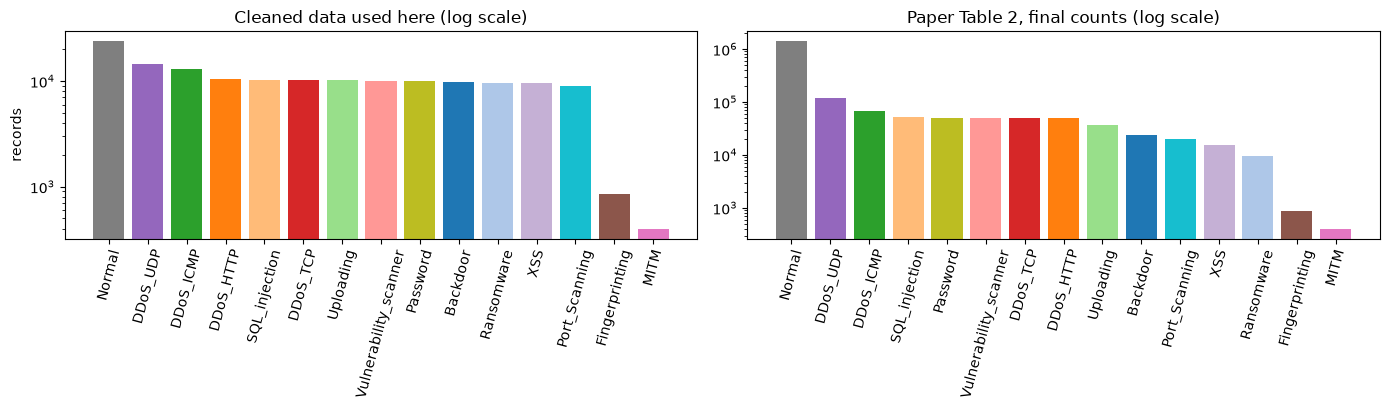

In [9]:
# Class distribution (paper Fig. 2) - bar chart of the real classes
counts = df[LABEL_COL].value_counts()
palette = plt.get_cmap("tab20")(np.array([0, 2, 4, 6, 8, 10, 12, 14, 16, 18, 1, 3, 5, 7, 9]))[:len(CLASSES)]   # 15 distinguishable colours
color_of = {c: palette[i] for i, c in enumerate(CLASSES)}
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
ax[0].bar(counts.index, counts.values, color=[color_of[c] for c in counts.index]); ax[0].set_yscale("log")
ax[0].set_title("Cleaned data used here (log scale)"); ax[0].tick_params(axis="x", rotation=75); ax[0].set_ylabel("records")
pc = pd.Series({k: v[1] for k, v in PAPER_T2.items()})
ax[1].bar(pc.index, pc.values, color=[color_of[c] for c in pc.index]); ax[1].set_yscale("log")
ax[1].set_title("Paper Table 2, final counts (log scale)"); ax[1].tick_params(axis="x", rotation=75)
plt.tight_layout(); plt.show()

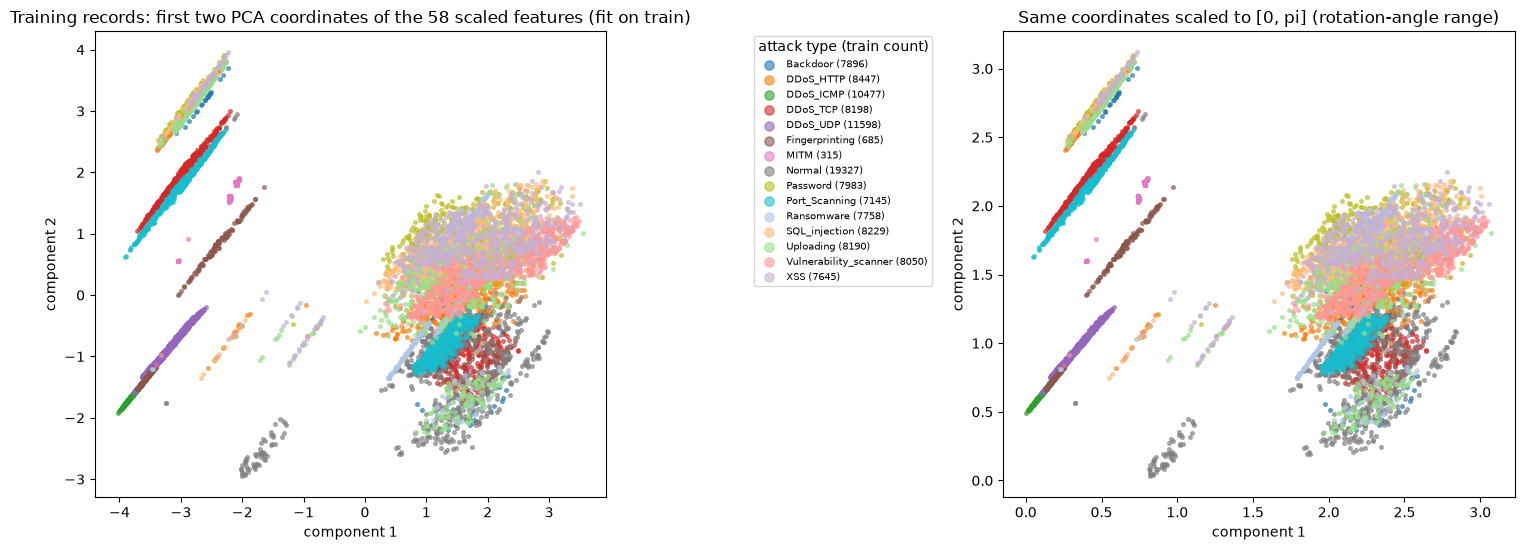

PCA explained variance of the two components: 42.9 %
(The model itself uses a learned 4-D latent code instead of PCA; that learned code is drawn after training.)


In [10]:
# 2-D scatter of real training records, coloured by ground-truth attack type
pca2 = PCA(n_components=2, random_state=SEED).fit(X_tr)                  # fitted on the training split only
Z_tr = pca2.transform(X_tr)
sel = []                                                                   # up to 700 records per class (all of the small classes)
r2 = np.random.default_rng(SEED)
for k in range(len(CLASSES)):
    ik = np.where(y_tr == k)[0]; sel.extend(r2.choice(ik, min(700, len(ik)), replace=False))
sel = np.array(sel)
ang = MinMaxScaler((0, np.pi)).fit(Z_tr)                                   # same two coordinates scaled to [0, pi]
Z_ang = np.clip(ang.transform(Z_tr), 0, np.pi)
fig, axs = plt.subplots(1, 2, figsize=(15, 5.6))
for k, c in enumerate(CLASSES):
    m = sel[y_tr[sel] == k]
    axs[0].scatter(Z_tr[m, 0], Z_tr[m, 1], s=7, alpha=0.6, color=color_of[c], label=f"{c} ({int((y_tr == k).sum())})")
    axs[1].scatter(Z_ang[m, 0], Z_ang[m, 1], s=7, alpha=0.6, color=color_of[c])
axs[0].set_title("Training records: first two PCA coordinates of the 58 scaled features (fit on train)")
axs[1].set_title("Same coordinates scaled to [0, pi] (rotation-angle range)")
for a in axs: a.set_xlabel("component 1"); a.set_ylabel("component 2")
axs[0].legend(markerscale=2.5, fontsize=7, loc="upper left", bbox_to_anchor=(1.28, 1.0), title="attack type (train count)", ncol=1)
plt.tight_layout(); plt.show()
print("PCA explained variance of the two components: %.1f %%" % (100 * pca2.explained_variance_ratio_.sum()))
print("(The model itself uses a learned 4-D latent code instead of PCA; that learned code is drawn after training.)")

## 3. The models (paper Section 3 and the ablation of Section 4.3)

* `FastVQC` is the quantum block. The circuit (drawn in the next section from the real PennyLane QNode) is: for each of the L layers, RY(z_k) angle embedding on all qubits (re-uploading), `Rot(alpha, beta, gamma)` on each qubit, then the CNOT ring 0->1->2->3->0; finally <Z_k> on every qubit. `FastVQC` computes exactly the same unitary with batched tensor operations in PyTorch so that training takes minutes, not hours (PennyLane's own broadcasting path needs about 1 ms per sample for the forward and backward pass). Equality with the PennyLane QNode is asserted in the next section.
* `HybridNet(kind)` builds the four paper variants: `rhq` (proposed), `rhq_simple` (one-time encoding + one trainable single-qubit layer: no re-uploading, no entanglement, 12 circuit parameters), `cls_res` (the quantum block replaced by a 48-parameter classical bottleneck), `dnn` (the Simple DNN, 58-128-64-32-15). `CNN1D` is the lightweight 1D-CNN of Table 7.

In [11]:
# 3a. Quantum block: PennyLane QNode (reference, used for the drawing and the equivalence test) and the fast exact simulator used for training
def make_qnode(n_qubits=N_QUBITS, n_layers=N_LAYERS, reupload=True, entangle=True):
    dev = qml.device("default.qubit", wires=n_qubits)
    @qml.qnode(dev, interface="torch", diff_method="backprop")
    def circuit(inputs, weights):
        for l in range(n_layers):
            if l == 0 or reupload:
                qml.AngleEmbedding(inputs, wires=range(n_qubits), rotation="Y")   # S(z) = tensor product of RY(z_k)  (Eq. 5)
            for k in range(n_qubits):
                qml.Rot(weights[l, k, 0], weights[l, k, 1], weights[l, k, 2], wires=k)   # R(alpha, beta, gamma)  (Eq. 6)
            if entangle:
                for k in range(n_qubits):
                    qml.CNOT(wires=[k, (k + 1) % n_qubits])                          # ring of CNOTs (Eq. 6)
        return [qml.expval(qml.PauliZ(k)) for k in range(n_qubits)]                  # q_k = <Z_k>  (Eq. 8)
    return circuit

def _cnot_ring_perm(n):
    perm = np.zeros(2 ** n, dtype=np.int64)
    for b in range(2 ** n):
        bits = [(b >> (n - 1 - k)) & 1 for k in range(n)]
        for k in range(n):
            c, t = k, (k + 1) % n
            if bits[c]: bits[t] ^= 1
        f = sum(bit << (n - 1 - k) for k, bit in enumerate(bits))
        perm[f] = b
    return torch.tensor(perm)

class FastVQC(nn.Module):
    """Exact batched state-vector simulation of the circuit of make_qnode (same gates, same wire order, same weight layout)."""
    def __init__(self, n_qubits=N_QUBITS, n_layers=N_LAYERS, reupload=True, entangle=True):
        super().__init__()
        self.n, self.L, self.reupload, self.entangle = n_qubits, n_layers, reupload, entangle
        self.weights = nn.Parameter(torch.rand(n_layers, n_qubits, 3) * 2 * math.pi)   # CHOICE: uniform [0, 2pi)
        self.register_buffer("perm", _cnot_ring_perm(n_qubits))
        self.register_buffer("zsign", torch.tensor([[1.0 - 2.0 * ((b >> (n_qubits - 1 - k)) & 1) for k in range(n_qubits)] for b in range(2 ** n_qubits)]))
    @staticmethod
    def _embed(z):                                       # batched RY(z_k) on every qubit, as one 2^n x 2^n matrix per sample
        c, s = torch.cos(z / 2), torch.sin(z / 2)
        U = torch.stack([torch.stack([c, -s], -1), torch.stack([s, c], -1)], -2)
        M = U[:, 0]
        for k in range(1, U.shape[1]):
            B, d = M.shape[0], M.shape[1]
            M = torch.einsum("bij,bkl->bikjl", M, U[:, k]).reshape(B, d * 2, d * 2)
        return M
    def _layer_unitary(self, w):                         # Rot on every qubit followed by the CNOT ring (PennyLane Rot convention)
        phi, th, om = w[:, 0], w[:, 1], w[:, 2]
        cc, ss = torch.cos(th / 2), torch.sin(th / 2)
        pol = lambda r, ang: torch.complex(r * torch.cos(ang), r * torch.sin(ang))   # (not torch.polar: its gradient is wrong for negative r)
        a = pol(cc, -(phi + om) / 2); b = -pol(ss, (phi - om) / 2); c = pol(ss, -(phi - om) / 2); d = pol(cc, (phi + om) / 2)
        U = torch.stack([torch.stack([a, b], -1), torch.stack([c, d], -1)], -2)
        K = reduce(torch.kron, [U[k] for k in range(self.n)])
        return K[self.perm] if self.entangle else K
    def forward(self, z):
        psi = None
        for l in range(self.L):
            if l == 0:
                psi = self._embed(z)[:, :, 0].to(torch.complex64)           # RY^(x)n acting on |0...0>
            elif self.reupload:
                psi = torch.bmm(self._embed(z).to(torch.complex64), psi.unsqueeze(-1)).squeeze(-1)
            psi = psi @ self._layer_unitary(self.weights[l]).T
        return (psi.abs() ** 2) @ self.zsign                                # <Z_k> for every qubit

class HybridNet(nn.Module):
    def __init__(self, kind, n_in=58, n_classes=15, nq=N_QUBITS):
        super().__init__()
        self.kind = kind
        if kind == "dnn":
            self.net = nn.Sequential(nn.Linear(n_in, 128), nn.ReLU(), nn.Linear(128, 64), nn.ReLU(), nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, n_classes))
            return
        self.encoder = nn.Sequential(nn.Linear(n_in, 128), nn.ReLU(), nn.Linear(128, 32), nn.ReLU(), nn.Linear(32, nq))   # Eq. 2
        if kind == "rhq":
            self.core = FastVQC(nq, N_LAYERS, reupload=True, entangle=True)
        elif kind == "rhq_simple":
            self.core = FastVQC(nq, 1, reupload=False, entangle=False)
        elif kind == "cls_res":                           # CHOICE: 3 x Linear(4,4, no bias) = 48 parameters, tanh in between
            self.core = nn.Sequential(nn.Linear(nq, nq, bias=False), nn.Tanh(), nn.Linear(nq, nq, bias=False), nn.Tanh(), nn.Linear(nq, nq, bias=False))
        self.post = nn.Linear(nq, nq)                     # Eq. 9
        self.head = nn.Sequential(nn.Linear(2 * nq, 16), nn.ReLU(), nn.Linear(16, n_classes))   # Eq. 11-12 (softmax inside the loss)
    def forward(self, x):
        if self.kind == "dnn":
            return self.net(x)
        z = math.pi * torch.tanh(self.encoder(x))         # Eq. 3
        q = self.core(z)
        qp = torch.relu(self.post(q))
        return self.head(torch.cat([z, qp], dim=1))       # Eq. 10 (residual fusion) + head

class CNN1D(nn.Module):
    def __init__(self, n_in=58, n_classes=15):
        super().__init__()
        self.f = nn.Sequential(nn.Conv1d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool1d(2), nn.Conv1d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool1d(2), nn.Flatten())
        self.c = nn.Sequential(nn.Linear(64 * (n_in // 2 // 2), 64), nn.ReLU(), nn.Linear(64, n_classes))
    def forward(self, x):
        return self.c(self.f(x.unsqueeze(1)))

def build(kind, seed):
    set_seed(seed)
    return CNN1D() if kind == "cnn1d" else HybridNet(kind)

n_par = lambda m: sum(p.numel() for p in m.parameters() if p.requires_grad)
PAPER_PARAMS = {"rhq": 12279, "rhq_simple": 12243, "cls_res": 12279, "dnn": 18383, "cnn1d": 64719}
for k in PAPER_PARAMS:
    m = build(k, SEED)
    extra = f" (circuit parameters: {m.core.weights.numel()})" if k.startswith("rhq") else ""
    print(f"{k:11s} trainable parameters = {n_par(m):6,d}   paper = {PAPER_PARAMS[k]:6,d}{extra}")

rhq         trainable parameters = 12,279   paper = 12,279 (circuit parameters: 48)
rhq_simple  trainable parameters = 12,243   paper = 12,243 (circuit parameters: 12)
cls_res     trainable parameters = 12,279   paper = 12,279
dnn         trainable parameters = 18,383   paper = 18,383
cnn1d       trainable parameters = 64,719   paper = 64,719


## Quantum Circuit Architecture

The drawings below are produced by `qml.draw_mpl` from the **real PennyLane QNodes** (`level="device"`, so the angle-embedding template is shown as the RY gates it applies). Two distinct architectures are used by the notebook: the proposed 4-qubit, 4-layer re-uploading circuit with entanglement, and the ablation circuit with a single encoding, one trainable single-qubit layer and no entanglers (paper Section 4.3).

Circuit details taken from the paper: angle embedding with Pauli-Y rotations (Eq. 5), a layer of general single-qubit rotations `Rot(alpha, beta, gamma)` followed by a CNOT ring (Eq. 6), measurement of <Z> on every qubit (Eq. 8), L = 4, 48 trainable parameters. **Assumptions where the paper is silent:** the CNOT ring is applied in the order (0,1), (1,2), (2,3), (3,0) after the rotations of the same layer; the initial state is |0000>; weights are initialised uniformly in [0, 2 pi); the simulator is ideal and exact (no shots, no noise), as in the paper.

The training loop uses `FastVQC`. The cell below proves that it computes the same function and the same gradients as the drawn QNodes.

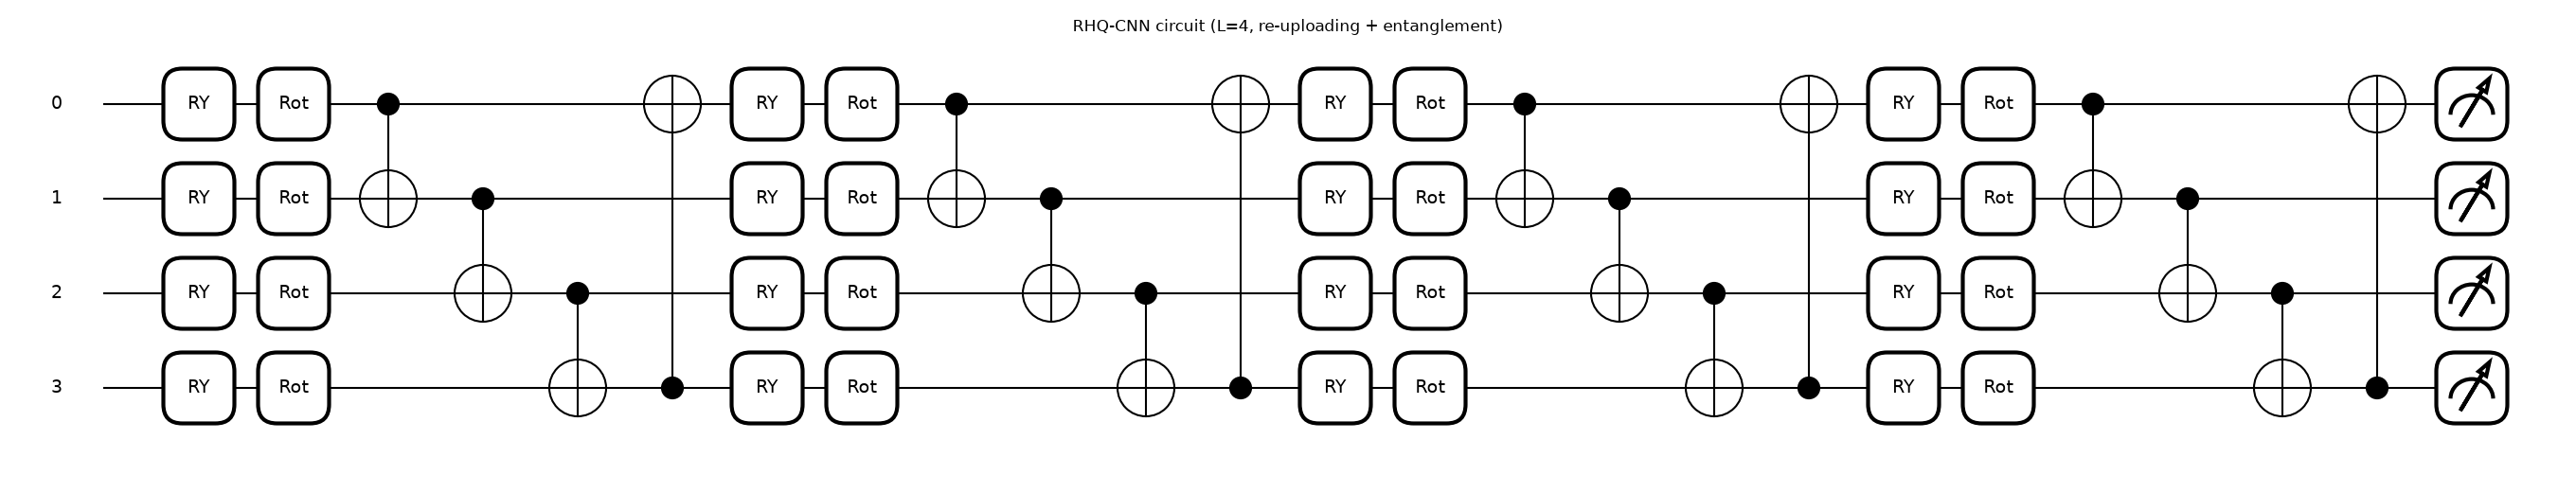

RHQ-CNN circuit (L=4, re-uploading + entanglement)
  qubits = 4 | depth = 24 | gates = 48 {'RY': 16, 'Rot': 16, 'CNOT': 16} | trainable parameters = 48 | measurements = <Z> on 4 qubits



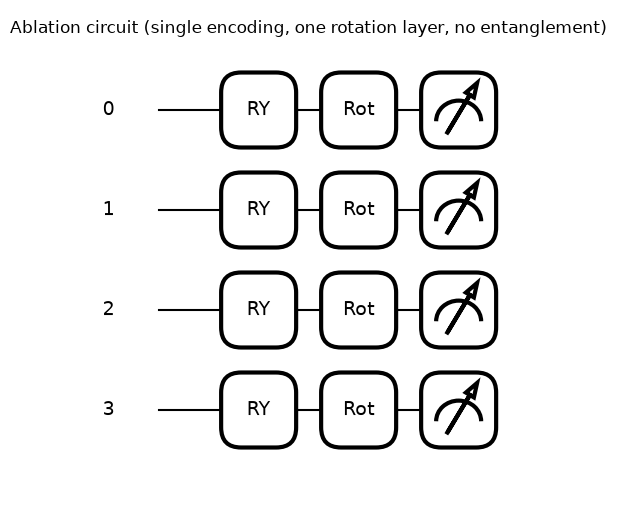

Ablation circuit (single encoding, one rotation layer, no entanglement)
  qubits = 4 | depth = 2 | gates = 8 {'RY': 4, 'Rot': 4} | trainable parameters = 12 | measurements = <Z> on 4 qubits



In [12]:
# Draw the circuits that are executed (PennyLane QNodes) and print qubit count, depth, parameter count
x_demo = torch.tensor([[0.3, -1.2, 2.0, 0.7]], dtype=torch.float32)
circuits = {"RHQ-CNN circuit (L=4, re-uploading + entanglement)": (N_LAYERS, True, True),
            "Ablation circuit (single encoding, one rotation layer, no entanglement)": (1, False, False)}
for name, (L, ru, en) in circuits.items():
    qn = make_qnode(N_QUBITS, L, ru, en)
    w_demo = torch.rand(L, N_QUBITS, 3) * 2 * math.pi
    fig, ax = qml.draw_mpl(qn, level="device")(x_demo, w_demo)
    fig.suptitle(name); plt.show()
    res = qml.specs(qn, level="device")(x_demo, w_demo)["resources"]
    print(f"{name}\n  qubits = {N_QUBITS} | depth = {res.depth} | gates = {res.num_gates} {dict(res.gate_types)} | trainable parameters = {w_demo.numel()} | measurements = <Z> on {N_QUBITS} qubits\n")

In [13]:
# Equivalence: FastVQC (used for training) == PennyLane QNode (drawn above), outputs and gradients
def check_equivalence(fast, L, ru, en, n=9, seed=0):
    g = torch.Generator().manual_seed(seed)
    z = (torch.rand(n, N_QUBITS, generator=g) * 2 - 1) * math.pi
    qn = make_qnode(N_QUBITS, L, ru, en)
    w = fast.weights.detach().clone()
    out_f = fast(z)
    out_q = torch.stack(qn(z, w), -1).float()
    gf = torch.autograd.grad(out_f.pow(2).sum(), fast.weights)[0]
    wq = w.clone().requires_grad_(True)
    gq = torch.autograd.grad(torch.stack(qn(z, wq), -1).pow(2).sum(), wq)[0]
    assert np.allclose(out_f.detach().numpy(), out_q.numpy(), atol=1e-5), "outputs differ"
    assert np.allclose(gf.numpy(), gq.numpy(), atol=1e-4), "gradients differ"
    return float((out_f - out_q).abs().max()), float((gf - gq).abs().max())

for name, (L, ru, en) in circuits.items():
    set_seed(SEED)
    d_out, d_grad = check_equivalence(FastVQC(N_QUBITS, L, ru, en), L, ru, en)
    print(f"EQUIVALENT (random weights): max |output diff| = {d_out:.1e}, max |gradient diff| = {d_grad:.1e}  <- {name}")

EQUIVALENT (random weights): max |output diff| = 3.4e-07, max |gradient diff| = 1.1e-06  <- RHQ-CNN circuit (L=4, re-uploading + entanglement)
EQUIVALENT (random weights): max |output diff| = 2.4e-07, max |gradient diff| = 2.6e-06  <- Ablation circuit (single encoding, one rotation layer, no entanglement)


## 4. Training machinery

Adam, cross-entropy, batches of 256, validation after every epoch, the weights with the lowest validation loss are restored at the end (paper Section 4.1). Training time per epoch is the pure fitting time (validation excluded). Inference latency is measured on the whole test set in batches of 4096.

In [14]:
# 4a. Training and evaluation helpers
Xf_t, yf_t = torch.from_numpy(X_fit), torch.from_numpy(y_fit).long()
Xv_t, yv_t = torch.from_numpy(X_val), torch.from_numpy(y_val).long()
Xt_t = torch.from_numpy(X_te)
loss_fn = nn.CrossEntropyLoss()

@torch.no_grad()
def predict_proba(model, X, bs=4096):
    model.eval(); out = []
    for i in range(0, len(X), bs):
        out.append(torch.softmax(model(X[i:i + bs]), dim=1))
    return torch.cat(out).numpy()

def fit(model, seed, epochs=EPOCHS, verbose=True, tag=""):
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    g = torch.Generator().manual_seed(seed)
    n = len(Xf_t); hist = []; best = (1e9, None); t_fit = 0.0; t_all = time.time()
    for ep in range(epochs):
        model.train(); t0 = time.time(); perm = torch.randperm(n, generator=g); tot = 0.0
        for i in range(0, n, BATCH_SIZE):
            b = perm[i:i + BATCH_SIZE]
            opt.zero_grad(); loss = loss_fn(model(Xf_t[b]), yf_t[b]); loss.backward(); opt.step()
            tot += loss.item() * len(b)
        t_ep = time.time() - t0; t_fit += t_ep
        model.eval()
        with torch.no_grad():
            lv = sum(loss_fn(model(Xv_t[i:i + 4096]), yv_t[i:i + 4096]).item() * len(Xv_t[i:i + 4096]) for i in range(0, len(Xv_t), 4096)) / len(Xv_t)
        acc_v = float((predict_proba(model, Xv_t).argmax(1) == y_val).mean())
        hist.append(dict(epoch=ep + 1, train_loss=tot / n, val_loss=lv, val_acc=acc_v, sec=t_ep))
        if lv < best[0]: best = (lv, copy.deepcopy(model.state_dict()))
        if verbose: print(f"  {tag} epoch {ep + 1:2d}/{epochs}  train loss {tot / n:.4f}  val loss {lv:.4f}  val acc {acc_v:.4f}  ({t_ep:.1f} s)")
    model.load_state_dict(best[1])
    return pd.DataFrame(hist), t_fit / epochs, time.time() - t_all

def metrics(y, prob):
    pred = prob.argmax(1)
    ap = np.mean([average_precision_score((y == k).astype(int), prob[:, k]) for k in range(prob.shape[1]) if (y == k).any()])
    return dict(accuracy=100 * accuracy_score(y, pred), macro_f1=100 * f1_score(y, pred, average="macro"),
                weighted_f1=100 * f1_score(y, pred, average="weighted"), macro_pr_auc=100 * ap)

def run_variant(kind, seed, verbose=True):
    model = build(kind, seed)
    hist, t_epoch, t_total = fit(model, seed, verbose=verbose, tag=f"[{kind} seed {seed}]")
    t0 = time.time(); prob = predict_proba(model, Xt_t); dt = time.time() - t0
    try:
        import psutil; rss = psutil.Process().memory_info().rss / 2 ** 20
    except Exception:
        rss = float("nan")
    r = dict(kind=kind, seed=seed, params=n_par(model), t_epoch=t_epoch, t_total_min=t_total / 60, latency_ms=1000 * dt / len(Xt_t),
             throughput=len(Xt_t) / dt, rss_mb=rss, **metrics(y_te, prob))
    return model, hist, prob, r
print("helpers ready; fitting rows:", len(Xf_t), "| validation rows:", len(Xv_t), "| test rows:", len(Xt_t))

helpers ready; fitting rows: 97554 | validation rows: 24389 | test rows: 30486


## 5. Train the four variants of the ablation (Tables 5-7) and the 1D-CNN

For each seed the four variants of Section 4.3 are trained on the same split. The first seed also supplies the confusion matrix, the per-class report, the deployment-cost numbers and the bootstrap. The 1D-CNN (Table 7) is trained for the first seed only.

In [15]:
# 5a. Main experiment
VARIANTS = {"rhq": "RHQ-CNN (proposed)", "rhq_simple": "RHQ-CNN w/o re-upload & entanglement", "cls_res": "Classical residual bottleneck", "dnn": "Simple DNN"}
models, hists, probs, rows = {}, {}, {}, []
t_start = time.time()
for si, seed in enumerate(SEEDS):
    for kind in VARIANTS:
        m, h, p, r = run_variant(kind, seed, verbose=(si == 0))
        rows.append(r); print(f"==> {VARIANTS[kind]:40s} seed {seed}: acc {r['accuracy']:.2f}  macro-F1 {r['macro_f1']:.2f}  ({r['t_total_min']:.1f} min)")
        if si == 0:
            models[kind], hists[kind], probs[kind] = m, h, p
            if kind.startswith("rhq"):            # the circuit that was trained is the circuit that was drawn
                L, ru, en = (N_LAYERS, True, True) if kind == "rhq" else (1, False, False)
                d = check_equivalence(m.core, L, ru, en, seed=1)
                print(f"    trained weights: FastVQC == PennyLane QNode (max output diff {d[0]:.1e}, max grad diff {d[1]:.1e})")
m, h, p, r = run_variant("cnn1d", SEEDS[0], verbose=False)
models["cnn1d"], hists["cnn1d"], probs["cnn1d"] = m, h, p; rows.append(r)
print(f"==> 1D-CNN seed {SEEDS[0]}: acc {r['accuracy']:.2f} macro-F1 {r['macro_f1']:.2f}")
res = pd.DataFrame(rows)
print("total time for this cell: %.1f min" % ((time.time() - t_start) / 60))

  [rhq seed 42] epoch  1/10  train loss 1.2282  val loss 0.5235  val acc 0.8318  (33.0 s)


  [rhq seed 42] epoch  2/10  train loss 0.3360  val loss 0.2325  val acc 0.9217  (48.5 s)


  [rhq seed 42] epoch  3/10  train loss 0.1569  val loss 0.1222  val acc 0.9569  (42.9 s)


  [rhq seed 42] epoch  4/10  train loss 0.1129  val loss 0.0820  val acc 0.9764  (45.7 s)


  [rhq seed 42] epoch  5/10  train loss 0.0814  val loss 0.1292  val acc 0.9595  (46.4 s)


...

==> RHQ-CNN (proposed)                       seed 44: acc 98.43  macro-F1 97.52  (13.8 min)


==> RHQ-CNN w/o re-upload & entanglement     seed 44: acc 98.01  macro-F1 96.96  (4.2 min)


==> Classical residual bottleneck            seed 44: acc 98.69  macro-F1 97.39  (0.9 min)


==> Simple DNN                               seed 44: acc 98.58  macro-F1 97.36  (0.7 min)


==> 1D-CNN seed 42: acc 98.56 macro-F1 97.04
total time for this cell: 55.3 min


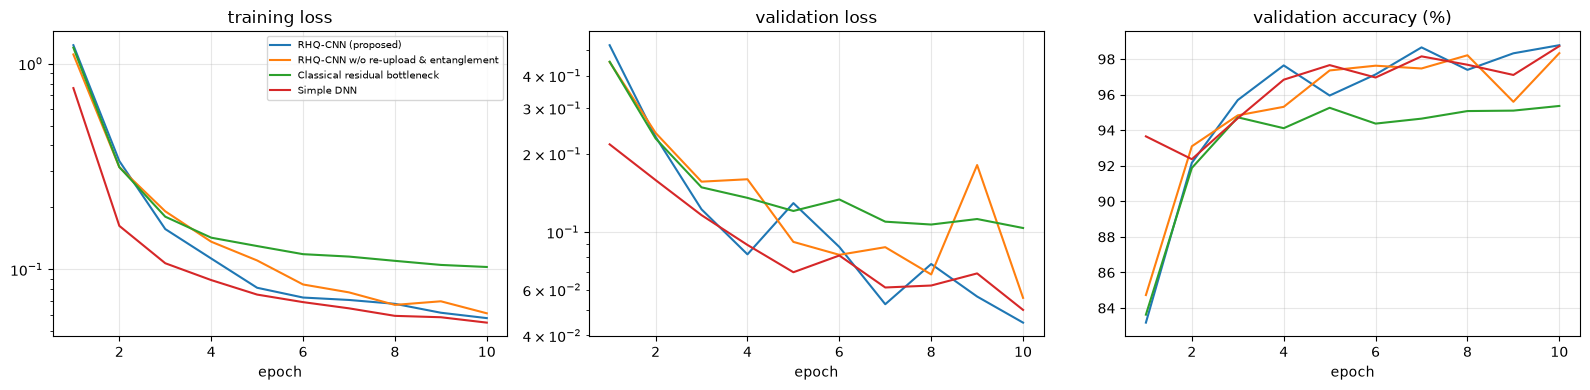

In [16]:
# 5b. Learning curves (first seed)
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for kind, name in VARIANTS.items():
    h = hists[kind]
    ax[0].plot(h.epoch, h.train_loss, label=name); ax[1].plot(h.epoch, h.val_loss, label=name); ax[2].plot(h.epoch, 100 * h.val_acc, label=name)
for a, t in zip(ax, ["training loss", "validation loss", "validation accuracy (%)"]):
    a.set_title(t); a.set_xlabel("epoch"); a.grid(alpha=.3)
ax[0].set_yscale("log"); ax[1].set_yscale("log"); ax[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

## 6. Per-class report and confusion matrix of the proposed RHQ-CNN (Table 5, Fig. 4)

,precision,recall,F1,support,paper_F1,F1_diff,paper_precision,paper_recall
Backdoor,0.9995,0.9995,0.9995,1974,0.9975,0.0020,0.9956,0.9994
DDoS_HTTP,0.9772,0.9957,0.9864,2112,0.9965,-0.0101,0.9961,0.9970
DDoS_ICMP,1.0000,0.9927,0.9964,2619,0.9981,-0.0017,0.9976,0.9986
DDoS_TCP,0.9927,0.9248,0.9576,2049,0.9997,-0.0421,0.9994,1.0000
DDoS_UDP,0.9993,1.0000,0.9997,2900,1.0000,-0.0003,1.0000,1.0000
Fingerprinting,0.8187,0.8713,0.8442,171,0.7099,0.1343,0.8525,0.6082
MITM,1.0000,0.8101,0.8951,79,0.9937,-0.0986,0.9875,1.0000
Normal,1.0000,0.9998,0.9999,4832,1.0000,-0.0001,1.0000,1.0000
Password,0.9995,0.9534,0.9759,1996,0.9982,-0.0223,0.9996,0.9968
Port_Scanning,0.9150,1.0000,0.9556,1786,0.9979,-0.0423,0.9965,0.9992


RHQ-CNN test accuracy 98.77 % | macro P/R/F1 = 0.9766 / 0.9678 / 0.9712 | weighted F1 98.77 % | macro PR-AUC 97.90 %


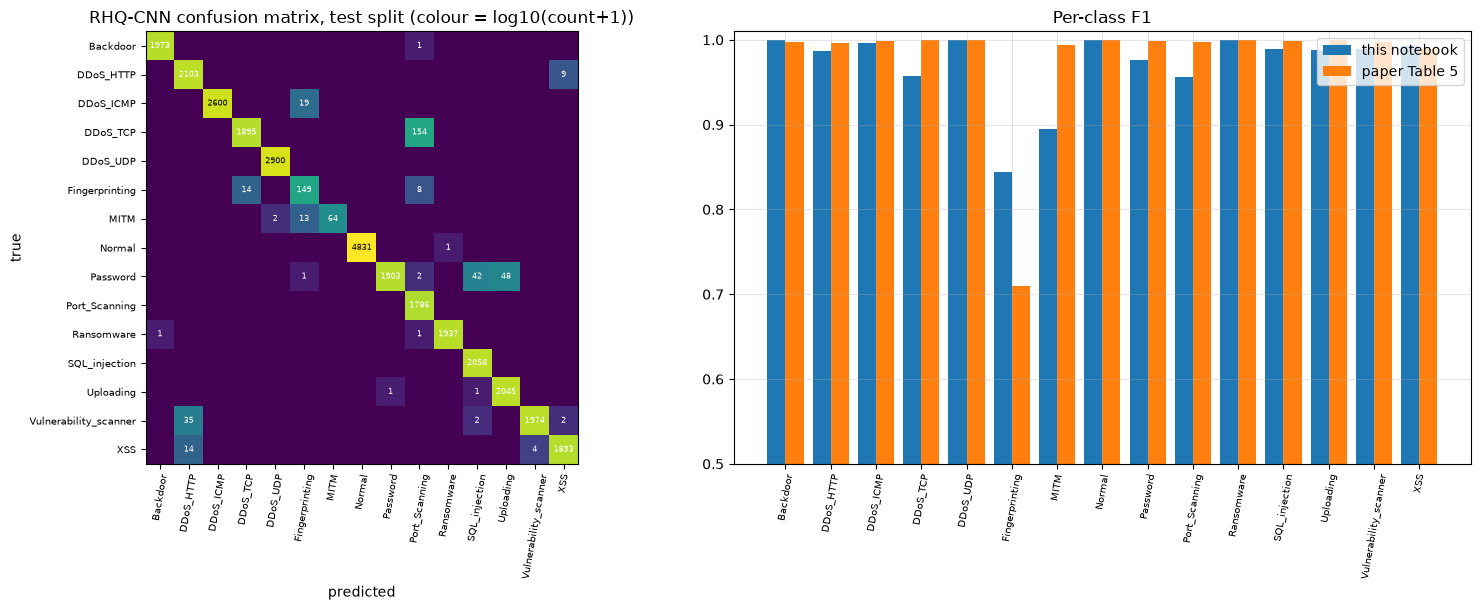

In [17]:
# 6a. Table 5 analogue and Fig. 4 analogue (first seed, held-out test split)
pred = probs["rhq"].argmax(1)
p, r_, f, s = precision_recall_fscore_support(y_te, pred, labels=range(len(CLASSES)), zero_division=0)
PAPER_T5 = {"Normal": (1.0, 1.0, 1.0), "DDoS_UDP": (1.0, 1.0, 1.0), "DDoS_ICMP": (.9976, .9986, .9981), "SQL_injection": (.9971, .9999, .9985),
            "Password": (.9996, .9968, .9982), "Vulnerability_scanner": (.9979, .9970, .9975), "DDoS_TCP": (.9994, 1.0, .9997),
            "DDoS_HTTP": (.9961, .9970, .9965), "Uploading": (.9992, .9996, .9994), "Backdoor": (.9956, .9994, .9975),
            "Port_Scanning": (.9965, .9992, .9979), "XSS": (.9891, .9881, .9886), "Ransomware": (1.0, .9995, .9997),
            "Fingerprinting": (.8525, .6082, .7099), "MITM": (.9875, 1.0, .9937)}
t5 = pd.DataFrame({"precision": p, "recall": r_, "F1": f, "support": s}, index=CLASSES).round(4)
t5["paper_F1"] = [PAPER_T5[c][2] for c in CLASSES]; t5["F1_diff"] = (t5["F1"] - t5["paper_F1"]).round(4)
t5["paper_precision"] = [PAPER_T5[c][0] for c in CLASSES]; t5["paper_recall"] = [PAPER_T5[c][1] for c in CLASSES]
display(t5)
mm = metrics(y_te, probs["rhq"])
print("RHQ-CNN test accuracy %.2f %% | macro P/R/F1 = %.4f / %.4f / %.4f | weighted F1 %.2f %% | macro PR-AUC %.2f %%" % (
    mm["accuracy"], p.mean(), r_.mean(), f.mean(), mm["weighted_f1"], mm["macro_pr_auc"]))

cm = confusion_matrix(y_te, pred, labels=range(len(CLASSES)))
fig, ax = plt.subplots(1, 2, figsize=(16, 6.2))
im = ax[0].imshow(np.log10(cm + 1), cmap="viridis")
ax[0].set_xticks(range(len(CLASSES))); ax[0].set_xticklabels(CLASSES, rotation=80, fontsize=7); ax[0].set_yticks(range(len(CLASSES))); ax[0].set_yticklabels(CLASSES, fontsize=7)
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        if cm[i, j]: ax[0].text(j, i, cm[i, j], ha="center", va="center", fontsize=6, color="w" if cm[i, j] < cm.max() / 2 else "k")
ax[0].set_xlabel("predicted"); ax[0].set_ylabel("true"); ax[0].set_title("RHQ-CNN confusion matrix, test split (colour = log10(count+1))")
x = np.arange(len(CLASSES)); ax[1].bar(x - .2, t5["F1"], .4, label="this notebook"); ax[1].bar(x + .2, t5["paper_F1"], .4, label="paper Table 5")
ax[1].set_xticks(x); ax[1].set_xticklabels(CLASSES, rotation=80, fontsize=7); ax[1].set_ylim(0.5, 1.01); ax[1].set_title("Per-class F1"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

### The learned latent space

The encoder maps every record to four angles z in [-pi, pi]. Here are the real test records, coloured by their true attack type, in the first two principal components of that learned latent code (compare with the raw-feature scatter above).

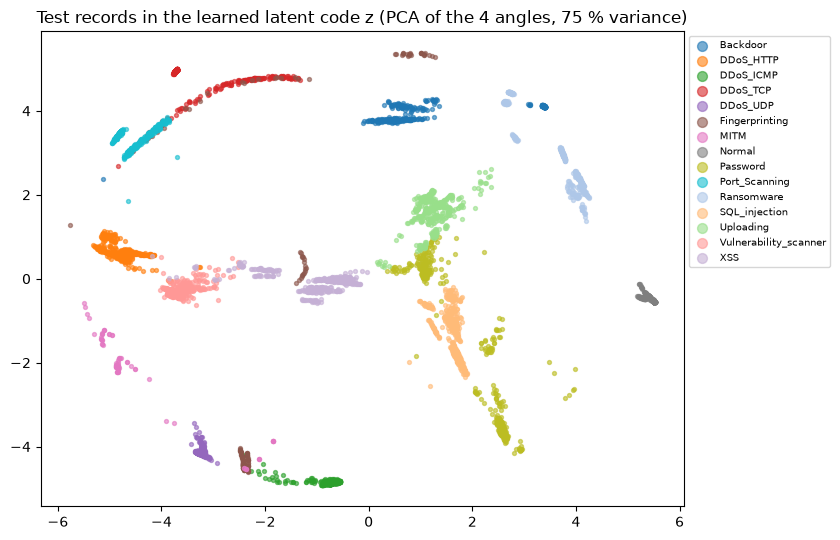

In [18]:
# 6b. Learned 4-D latent code of the proposed model, PCA to 2-D, test records coloured by ground truth
with torch.no_grad():
    models["rhq"].eval(); Z_lat = (math.pi * torch.tanh(models["rhq"].encoder(Xt_t))).numpy()
sel_t = []
for k in range(len(CLASSES)):
    ik = np.where(y_te == k)[0]; sel_t.extend(r2.choice(ik, min(400, len(ik)), replace=False))
sel_t = np.array(sel_t)
pl = PCA(2, random_state=SEED).fit(Z_lat)
Zp = pl.transform(Z_lat)
fig, ax = plt.subplots(figsize=(8.5, 5.5))
for k, c in enumerate(CLASSES):
    m = sel_t[y_te[sel_t] == k]
    ax.scatter(Zp[m, 0], Zp[m, 1], s=8, alpha=.6, color=color_of[c], label=c)
ax.set_title("Test records in the learned latent code z (PCA of the 4 angles, %.0f %% variance)" % (100 * pl.explained_variance_ratio_.sum()))
ax.legend(markerscale=2.5, fontsize=7, loc="upper left", bbox_to_anchor=(1.0, 1.0)); plt.tight_layout(); plt.show()

## 7. Ablation (paper Table 6)

The four variants on the same split. With several seeds the table shows mean +/- standard deviation over initialisation/shuffling seeds (the paper reports a single run and says run-to-run variability was left for future work).

,variant,params (ours),params (paper),acc % (ours),macro-F1 % (ours),acc % (paper),macro-F1 % (paper),runs
0,Simple DNN,18383,18383,98.50 +/- 0.23,97.42 +/- 0.39,98.67,93.45,3
1,Classical residual bottleneck,12279,12279,97.43 +/- 1.30,95.66 +/- 1.43,96.72,84.83,3
2,RHQ-CNN w/o re-upload & entanglement,12243,12243,98.34 +/- 0.31,97.26 +/- 0.21,97.13,85.94,3
3,RHQ-CNN (proposed),12279,12279,98.41 +/- 0.30,97.15 +/- 0.29,99.94,97.83,3


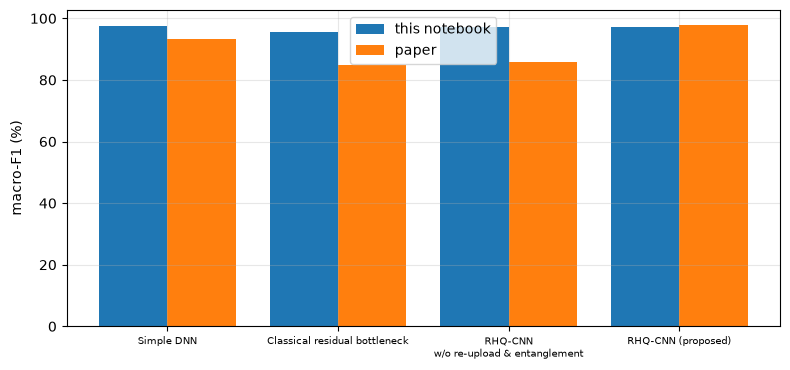

In [19]:
# 7a. Table 6 analogue
PAPER_T6 = {"dnn": (98.67, 93.45), "cls_res": (96.72, 84.83), "rhq_simple": (97.13, 85.94), "rhq": (99.94, 97.83)}
tab6 = []
for kind in ["dnn", "cls_res", "rhq_simple", "rhq"]:
    d = res[res.kind == kind]
    tab6.append({"variant": VARIANTS[kind], "params (ours)": int(d.params.iloc[0]), "params (paper)": PAPER_PARAMS[kind],
                 "acc % (ours)": f"{d.accuracy.mean():.2f}" + (f" +/- {d.accuracy.std(ddof=0):.2f}" if len(d) > 1 else ""),
                 "macro-F1 % (ours)": f"{d.macro_f1.mean():.2f}" + (f" +/- {d.macro_f1.std(ddof=0):.2f}" if len(d) > 1 else ""),
                 "acc % (paper)": PAPER_T6[kind][0], "macro-F1 % (paper)": PAPER_T6[kind][1], "runs": len(d)})
tab6 = pd.DataFrame(tab6); display(tab6)
fig, ax = plt.subplots(figsize=(8, 3.8)); x = np.arange(4); ks = ["dnn", "cls_res", "rhq_simple", "rhq"]
ax.bar(x - .2, [res[res.kind == k].macro_f1.mean() for k in ks], .4, label="this notebook"); ax.bar(x + .2, [PAPER_T6[k][1] for k in ks], .4, label="paper")
ax.set_xticks(x); ax.set_xticklabels([VARIANTS[k].replace(" w/o", "\nw/o") for k in ks], fontsize=7); ax.set_ylabel("macro-F1 (%)"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 8. Classical baselines on the identical inputs and the deployment-cost comparison (Table 7)

Every model sees the same 58 scaled features (the quantum model's encoder sees them too). Besides the paper's classical comparators (Classical DNN = the Simple DNN above, XGBoost, 1D-CNN) we add a Random Forest, an RBF-SVM (trained on a random subset because it scales quadratically) and a Random Forest on only **four PCA components** (a linear 4-D bottleneck, fitted on the training split) to show what four dimensions alone can do.

In [20]:
# 8a. Classical baselines (same inputs)
base = []
def add_base(name, model, Xa, Xb, ya, extra=""):
    t0 = time.time(); model.fit(Xa, ya); t_fit = time.time() - t0
    t0 = time.time(); prob = model.predict_proba(Xb) if hasattr(model, "predict_proba") else None; dt = time.time() - t0
    if prob is None:
        pr = model.predict(Xb); prob = np.eye(len(CLASSES))[pr]
    r = dict(name=name, fit_s=t_fit, latency_ms=1000 * dt / len(Xb), **metrics(y_te, prob)); base.append(r)
    print(f"{name:28s} acc {r['accuracy']:.2f}  macro-F1 {r['macro_f1']:.2f}  fit {t_fit:.0f} s {extra}")
    return prob
prob_xgb = add_base("XGBoost", XGBClassifier(n_estimators=XGB_TREES, max_depth=6, tree_method="hist", n_jobs=2, random_state=SEED, objective="multi:softprob"), X_fit, X_te, y_fit)
prob_rf = add_base("Random Forest", RandomForestClassifier(n_estimators=RF_TREES, n_jobs=2, random_state=SEED), X_fit, X_te, y_fit)
sub = np.random.default_rng(SEED).choice(len(X_fit), min(SVC_TRAIN_CAP, len(X_fit)), replace=False)
prob_svc = add_base("SVC (rbf, subset)", SVC(kernel="rbf", C=1.0, probability=False, random_state=SEED), X_fit[sub], X_te, y_fit[sub], extra=f"(trained on {len(sub):,} rows)")
pca4 = PCA(4, random_state=SEED).fit(X_fit)
prob_rf4 = add_base("RF on 4 PCA components", RandomForestClassifier(n_estimators=RF_TREES, n_jobs=2, random_state=SEED), pca4.transform(X_fit), pca4.transform(X_te), y_fit)
base = pd.DataFrame(base); display(base.round(3))

XGBoost                      acc 99.95  macro-F1 99.77  fit 255 s 


Random Forest                acc 99.97  macro-F1 99.92  fit 68 s 


SVC (rbf, subset)            acc 94.22  macro-F1 90.32  fit 35 s (trained on 20,000 rows)


RF on 4 PCA components       acc 95.20  macro-F1 91.04  fit 139 s 


,name,fit_s,latency_ms,accuracy,macro_f1,weighted_f1,macro_pr_auc
0,XGBoost,254.776,0.096,99.948,99.769,99.948,99.983
1,Random Forest,67.901,0.111,99.970,99.916,99.970,99.967
2,"SVC (rbf, subset)",34.643,0.000,94.217,90.317,94.047,84.938
3,RF on 4 PCA components,139.076,0.146,95.204,91.038,95.093,93.867


In [21]:
# 8b. Table 7 analogue (first seed)
def row(kind, name):
    r = res[(res.kind == kind) & (res.seed == SEEDS[0])].iloc[0]
    return {"model": name, "params": int(r.params), "model size MB (fp32 weights)": round(r.params * 4 / 1e6, 3), "train s/epoch": round(r.t_epoch, 1),
            "total train min": round(r.t_total_min, 2), "latency ms/sample": round(r.latency_ms, 4), "throughput /s": int(r.throughput),
            "RSS MB": round(r.rss_mb), "acc %": round(r.accuracy, 2), "macro-F1 %": round(r.macro_f1, 2)}
t7 = [row("dnn", "Classical DNN"), None, row("cnn1d", "Lightweight 1D-CNN"), row("rhq", "RHQ-CNN")]
bx = base[base.name == "XGBoost"].iloc[0]
t7[1] = {"model": "XGBoost", "params": "N/A", "model size MB (fp32 weights)": "N/A", "train s/epoch": "N/A", "total train min": round(bx.fit_s / 60, 2),
         "latency ms/sample": round(bx.latency_ms, 4), "throughput /s": int(1000 / bx.latency_ms), "RSS MB": "-", "acc %": round(bx.accuracy, 2), "macro-F1 %": round(bx.macro_f1, 2)}
t7 = pd.DataFrame(t7); display(t7)
PAPER_T7 = pd.DataFrame({"model": ["Classical DNN", "XGBoost", "Lightweight 1D-CNN", "RHQ-CNN"], "params": [18383, "N/A", 64719, 12279], "size MB": [.24, 1.90, .78, .18],
                         "train s/epoch": [69.29, "N/A", 76.45, 125.26], "total min": [11.56, 5.58, 12.75, 20.88], "latency ms": [.0350, .0221, .0374, .0846],
                         "acc %": [98.67, 98.85, 99.41, 99.94], "macro-F1 %": [93.45, 96.49, 95.62, 97.83]})
print("Paper Table 7 (hardware: not stated; TensorFlow + PennyLane simulator):"); display(PAPER_T7)

,model,params,model size MB (fp32 weights),train s/epoch,total train min,latency ms/sample,throughput /s,RSS MB,acc %,macro-F1 %
0,Classical DNN,18383,0.074,2.7,0.47,0.0034,291989,100,98.73,97.92
1,XGBoost,N/A,N/A,N/A,4.25,0.0958,10438,-,99.95,99.77
2,Lightweight 1D-CNN,64719,0.259,36.1,7.41,0.1681,5949,88,98.56,97.04
3,RHQ-CNN,12279,0.049,46.3,8.30,0.0586,17053,79,98.77,97.12


Paper Table 7 (hardware: not stated; TensorFlow + PennyLane simulator):


,model,params,size MB,train s/epoch,total min,latency ms,acc %,macro-F1 %
0,Classical DNN,18383,0.24,69.29,11.56,0.0350,98.67,93.45
1,XGBoost,N/A,1.90,N/A,5.58,0.0221,98.85,96.49
2,Lightweight 1D-CNN,64719,0.78,76.45,12.75,0.0374,99.41,95.62
3,RHQ-CNN,12279,0.18,125.26,20.88,0.0846,99.94,97.83


## 9. Statistical reliability: class-wise bootstrap (paper Table 8)

As in Section 4.5, the held-out test predictions are resampled with replacement **within each class** (no retraining) and Accuracy, Macro-F1 and Macro PR-AUC are recomputed; the 2.5th and 97.5th percentiles give the 95 % interval. As the paper itself notes, this measures test-set sampling variability only, not run-to-run variability.

In [22]:
# 9a. Bootstrap CI for the proposed model (first seed)
prob = probs["rhq"]; pred = prob.argmax(1); K = len(CLASSES)
cls_idx = [np.where(y_te == k)[0] for k in range(K)]
rb = np.random.default_rng(SEED); boot = []
t0 = time.time()
for b in range(N_BOOT):
    ii = np.concatenate([rb.choice(ix, len(ix), replace=True) for ix in cls_idx])
    yt, yp, pp = y_te[ii], pred[ii], prob[ii]
    cmb = np.bincount(yt * K + yp, minlength=K * K).reshape(K, K)
    tp = np.diag(cmb).astype(float); prec = tp / np.maximum(cmb.sum(0), 1); rec = tp / np.maximum(cmb.sum(1), 1)
    f1 = np.where(prec + rec > 0, 2 * prec * rec / np.maximum(prec + rec, 1e-12), 0)
    ap = np.mean([average_precision_score((yt == k).astype(int), pp[:, k]) for k in range(K)])
    boot.append((100 * tp.sum() / len(yt), 100 * f1.mean(), 100 * ap))
boot = np.array(boot); pt = metrics(y_te, prob)
ci = pd.DataFrame({"metric": ["Accuracy", "Macro F1", "Macro PR-AUC"], "point estimate %": [pt["accuracy"], pt["macro_f1"], pt["macro_pr_auc"]],
                   "CI low %": np.percentile(boot, 2.5, axis=0), "CI high %": np.percentile(boot, 97.5, axis=0),
                   "paper point %": [99.94, 97.83, 99.18], "paper CI low %": [99.94, 97.38, 98.94], "paper CI high %": [99.95, 98.23, 99.39]}).round(2)
display(ci); print(f"{N_BOOT} class-wise bootstrap resamples in {time.time() - t0:.0f} s")

,metric,point estimate %,CI low %,CI high %,paper point %,paper CI low %,paper CI high %
0,Accuracy,98.77,98.65,98.91,99.94,99.94,99.95
1,Macro F1,97.12,96.57,97.61,97.83,97.38,98.23
2,Macro PR-AUC,97.90,97.39,98.44,99.18,98.94,99.39


300 class-wise bootstrap resamples in 135 s


## 10. Side-by-side comparison with the paper

Rule from the project brief: a number is **reproduced** when it lies within 2 percentage points (0.02 on F1) of the paper's value, otherwise **not reached** (ours lower) or **exceeded** (ours higher), with the gap. Hardware-dependent timings and the qualitative SHAP figures **cannot be checked** here. Remember that the data differ from the paper's (see the data note at the top): the class mix is much more balanced here, and the training budget is the one in the configuration cell.

For the four ablation variants the notebook value is the **mean over the three seeds**; for the per-class rows, Table 5/7 baselines and the bootstrap it is the first seed (42) or the single run.

In [23]:
# 10a. Verdicts
def verdict(paper, ours, tol=2.0):
    g = ours - paper
    if abs(g) <= tol: return f"reproduced (gap {g:+.2f})"
    return f"{'exceeded' if g > 0 else 'not reached'} (gap {g:+.2f})"
R = lambda kind: res[res.kind == kind]
mean_ = lambda kind, col: R(kind)[col].mean()
rows = []
def claim(c, paper, ours, tol=2.0, unit="%"):
    rows.append({"claim": c, "paper": paper, "this notebook": round(ours, 2), "verdict": verdict(paper, ours, tol)})
claim("RHQ-CNN test accuracy (Tab. 5/6/8)", 99.94, mean_("rhq", "accuracy"))
claim("RHQ-CNN macro-F1 (Tab. 5/6/8)", 97.83, mean_("rhq", "macro_f1"))
claim("RHQ-CNN weighted-F1 (Tab. 5/9)", 99.94, mean_("rhq", "weighted_f1"))
claim("RHQ-CNN macro PR-AUC (Tab. 8)", 99.18, mean_("rhq", "macro_pr_auc"))
for c, pc in [("Fingerprinting", "F1 0.7099"), ("MITM", "F1 0.9937"), ("SQL_injection", "F1 0.9985"), ("XSS", "F1 0.9886")]:
    claim(f"{c} class F1 (Tab. 5), x100", 100 * PAPER_T5[c][2], 100 * float(t5.loc[c, "F1"]))
claim("Simple DNN accuracy (Tab. 6)", 98.67, mean_("dnn", "accuracy")); claim("Simple DNN macro-F1 (Tab. 6)", 93.45, mean_("dnn", "macro_f1"))
claim("Classical residual bottleneck accuracy (Tab. 6)", 96.72, mean_("cls_res", "accuracy")); claim("Classical residual bottleneck macro-F1 (Tab. 6)", 84.83, mean_("cls_res", "macro_f1"))
claim("RHQ w/o re-upload & entanglement accuracy (Tab. 6)", 97.13, mean_("rhq_simple", "accuracy")); claim("RHQ w/o re-upload & entanglement macro-F1 (Tab. 6)", 85.94, mean_("rhq_simple", "macro_f1"))
claim("XGBoost accuracy (Tab. 7)", 98.85, bx.accuracy); claim("XGBoost macro-F1 (Tab. 7)", 96.49, bx.macro_f1)
cn = res[res.kind == "cnn1d"].iloc[0]
claim("1D-CNN accuracy (Tab. 7)", 99.41, cn.accuracy); claim("1D-CNN macro-F1 (Tab. 7)", 95.62, cn.macro_f1)
for k in ["rhq", "rhq_simple", "cls_res", "dnn", "cnn1d"]:
    rows.append({"claim": f"parameter count {k} (Tab. 6/7)", "paper": PAPER_PARAMS[k], "this notebook": int(R(k).params.iloc[0]),
                 "verdict": "reproduced (exact)" if int(R(k).params.iloc[0]) == PAPER_PARAMS[k] else "not equal"})
f1s = {k: mean_(k, "macro_f1") for k in VARIANTS}
rows.append({"claim": "ablation order: full RHQ-CNN has the best macro-F1 of the 4 variants (Tab. 6)", "paper": "yes", "this notebook": ", ".join(f"{k}={v:.1f}" for k, v in f1s.items()),
             "verdict": "reproduced" if max(f1s, key=f1s.get) == "rhq" else "not reached (another variant is better)"})
f1t7 = {"DNN": mean_("dnn", "macro_f1"), "XGBoost": bx.macro_f1, "1D-CNN": cn.macro_f1, "RHQ-CNN": mean_("rhq", "macro_f1")}
rows.append({"claim": "RHQ-CNN has the best macro-F1 among DNN/XGBoost/1D-CNN (Tab. 7)", "paper": "yes", "this notebook": ", ".join(f"{k}={v:.1f}" for k, v in f1t7.items()),
             "verdict": "reproduced" if max(f1t7, key=f1t7.get) == "RHQ-CNN" else "not reached (another model is better)"})
weak = CLASSES[int(np.argmin(t5["F1"].to_numpy()))]
rows.append({"claim": "Fingerprinting is the hardest class (lowest F1)", "paper": "Fingerprinting", "this notebook": weak, "verdict": "reproduced" if weak == "Fingerprinting" else "not reached (hardest class differs)"})
w_acc = float(ci.loc[0, "CI high %"] - ci.loc[0, "CI low %"]); w_f1 = float(ci.loc[1, "CI high %"] - ci.loc[1, "CI low %"])
rows.append({"claim": "bootstrap 95 % CI widths are narrow (acc 0.01, macro-F1 0.85 points)", "paper": "0.01 / 0.85", "this notebook": f"{w_acc:.2f} / {w_f1:.2f}", "verdict": "reproduced (narrow, < 2 points)" if max(w_acc, w_f1) < 2 else "not reached"})
rows.append({"claim": "train time per epoch 125 s, latency 0.0846 ms/sample (Tab. 7)", "paper": "125.26 s / 0.0846 ms", "this notebook": f"{R('rhq').t_epoch.iloc[0]:.1f} s / {R('rhq').latency_ms.iloc[0]:.4f} ms",
             "verdict": "cannot be checked (different hardware, data size and simulator path)"})
rows.append({"claim": "RHQ-CNN is slower than the classical models (Tab. 7)", "paper": "yes", "this notebook": f"RHQ {R('rhq').t_epoch.iloc[0]:.1f} s/epoch vs DNN {R('dnn').t_epoch.iloc[0]:.1f} s", "verdict": "reproduced" if R('rhq').t_epoch.iloc[0] > R('dnn').t_epoch.iloc[0] else "not reached"})
rows.append({"claim": "SHAP importance / t-SNE of explanations (Figs. 5-6)", "paper": "qualitative", "this notebook": "not run", "verdict": "cannot be checked"})
comparison = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 90, "display.width", 250); display(comparison)
print(comparison["verdict"].str.split(" ").str[0].value_counts().to_string())

,claim,paper,this notebook,verdict
0,RHQ-CNN test accuracy (Tab. 5/6/8),99.94,98.41,reproduced (gap -1.53)
1,RHQ-CNN macro-F1 (Tab. 5/6/8),97.83,97.15,reproduced (gap -0.68)
2,RHQ-CNN weighted-F1 (Tab. 5/9),99.94,98.41,reproduced (gap -1.53)
3,RHQ-CNN macro PR-AUC (Tab. 8),99.18,98.24,reproduced (gap -0.94)
4,"Fingerprinting class F1 (Tab. 5), x100",70.99,84.42,exceeded (gap +13.43)
5,"MITM class F1 (Tab. 5), x100",99.37,89.51,not reached (gap -9.86)
6,"SQL_injection class F1 (Tab. 5), x100",99.85,98.92,reproduced (gap -0.93)
7,"XSS class F1 (Tab. 5), x100",98.86,99.24,reproduced (gap +0.38)
8,Simple DNN accuracy (Tab. 6),98.67,98.5,reproduced (gap -0.17)
9,Simple DNN macro-F1 (Tab. 6),93.45,97.42,exceeded (gap +3.97)


verdict
reproduced    20
exceeded       5
not            3
cannot         2


## 11. Reading the paper critically

1. **The data are not the paper's data here, and the class mix matters.** In the paper, 72 % of the test set is Normal traffic, so accuracy (99.94 %) and weighted-F1 are dominated by classes that every model gets right; macro-F1 and the two rarest classes are the informative numbers. In the public ML table the big classes are down-sampled, accuracy is therefore a harder, more balanced statistic, and Fingerprinting/MITM are a larger share of the test set.
2. **The ablation does not isolate "quantum".** The three controls differ from the full model in more than the quantum block: the classical residual bottleneck is a bias-free 4 -> 4 -> 4 -> 4 map (48 parameters), the "no re-uploading/no entanglement" variant has only 12 circuit parameters, and training lengths are not given. A like-for-like test would give the classical block a comparable non-linear capacity (for example the same number of non-linear layers with biases), train every variant for the same tuned budget, and report several seeds. The paper reports one run; run-to-run variance (which this notebook measures with `SEEDS`) is exactly what the huge swings between 96.7 % and 99.94 % could hide.
3. **The residual path lets the head ignore the circuit.** The classifier receives z directly (4 of its 8 inputs). A fair question is whether the head uses q' at all; Exercise 2 asks you to zero it.
4. **Idealised simulator only.** No shot noise, no gate noise, no hardware. The paper says so itself; the "NISQ-compatible" label refers to using four qubits, not to any noisy evaluation. Exercise 3 adds shot noise.
5. **Edge-IIoTset shortcuts.** Several columns (`tcp.srcport`, `tcp.payload`, `http.request.uri.query`, `mqtt.msg`, ...) carry attack-tool fingerprints, and many classical models reach > 99 % on this table. A near-perfect score says as much about the data as about the model; the paper's own Table 9 shows classical methods at the same level, so the "quantum contribution" is not what makes the model accurate on the majority classes.
6. **Timing comparison.** 125 s per epoch versus 69 s for the classical DNN depends on how the simulator is called (per-sample circuit evaluation vs batching) and on the hardware; it says nothing about quantum hardware cost.
7. **Unstated details.** Encoding of text columns, number of epochs, batch size, learning rate, XGBoost settings and the exact classical bottleneck are not given; this notebook documents each choice in the table at the top.

In [24]:
# 11a. What this run says (numbers computed above, nothing typed by hand)
r = res[res.kind == "rhq"]; d = res[res.kind == "dnn"]; s_ = res[res.kind == "rhq_simple"]; c_ = res[res.kind == "cls_res"]
print(f"RHQ-CNN macro-F1 {r.macro_f1.mean():.2f} | Simple DNN {d.macro_f1.mean():.2f} | classical residual {c_.macro_f1.mean():.2f} | RHQ w/o re-upload & entanglement {s_.macro_f1.mean():.2f}")
if len(SEEDS) > 1:
    print("macro-F1 standard deviation across seeds:", {VARIANTS[k]: round(res[res.kind == k].macro_f1.std(ddof=0), 2) for k in VARIANTS})
print("Random Forest macro-F1 %.2f | XGBoost %.2f | RF on only 4 PCA components %.2f" % (base.set_index("name").loc["Random Forest", "macro_f1"], bx.macro_f1, base.set_index("name").loc["RF on 4 PCA components", "macro_f1"]))
print("share of the test set that is Normal traffic: %.1f %% (paper: 72.4 %%)" % (100 * (y_te == class_to_id["Normal"]).mean()))

RHQ-CNN macro-F1 97.15 | Simple DNN 97.42 | classical residual 95.66 | RHQ w/o re-upload & entanglement 97.26
macro-F1 standard deviation across seeds: {'RHQ-CNN (proposed)': np.float64(0.29), 'RHQ-CNN w/o re-upload & entanglement': np.float64(0.21), 'Classical residual bottleneck': np.float64(1.43), 'Simple DNN': np.float64(0.39)}
Random Forest macro-F1 99.92 | XGBoost 99.77 | RF on only 4 PCA components 91.04
share of the test set that is Normal traffic: 15.8 % (paper: 72.4 %)


### What the committed full run shows (3 seeds, 10 epochs, all 152,429 cleaned rows)

* **Headline claims: reproduced within tolerance.** RHQ-CNN reaches 98.41 +/- 0.30 % accuracy and 97.15 +/- 0.29 % macro-F1 (paper: 99.94 % / 97.83 %), macro PR-AUC 98.24 % (paper 99.18 %). Fingerprinting is the hardest class here too (F1 0.844; the paper's 0.710 is worse), SQL injection and XSS are about 0.99.
* **The ablation story is not reproduced.** The three controls are *not* clearly worse than the full model: Simple DNN 97.42 +/- 0.39 %, RHQ without re-uploading/entanglement 97.26 +/- 0.21 %, full RHQ-CNN 97.15 +/- 0.29 % macro-F1; only the 48-parameter classical bottleneck is lower (95.66 +/- 1.43 %, and it is the least stable). The three leaders differ by less than one standard deviation. The paper's controls score 85-93 % macro-F1, far below ours, which suggests that their weaker variants were under-trained or unstable in their run rather than limited by classical capacity.
* **The RHQ-CNN does not have the best macro-F1 among the baselines.** XGBoost (99.77 %) and Random Forest (99.92 %) on the same 58 features are clearly better on this table; the 1D-CNN (97.04 %) is on par.
* **Bootstrap intervals are narrow** (accuracy 98.65-98.91 %, macro-F1 96.57-97.61 %), as in the paper, but they only describe test-sampling noise; the seed-to-seed standard deviation (about 0.3 points) is of the same size as the width of these intervals.
* **Cost.** The quantum model needs 46 s per epoch against 2.7 s for the classical DNN in our simulator, so the qualitative claim "slower than classical" holds; absolute times are not comparable with the paper's. (The "latency" of the SVC in the baseline table is not measured and shows 0.)
* **Data caveat.** Normal traffic is only 15.8 % of our test split (paper 72.4 %); MITM has 79 test records (one of them changes its recall by 1.3 points), which explains the noisy MITM F1 of 0.895 against 0.994.

## 12. Exercises

1. **Depth.** Change `N_LAYERS` to 1, 2, 6, 8 and plot macro-F1 against depth. Does re-uploading help, or is the encoder already doing the work? (Check parameters and run time too.)
2. **Is the quantum branch used?** After training the RHQ-CNN, multiply `q'` by zero at inference (`models["rhq"].post.weight.data.zero_()` and bias zero) and re-evaluate. Compare with the classical residual bottleneck.
3. **Shot noise.** Replace the exact expectation values by estimates from 100 / 1,000 / 10,000 shots (sample from `psi.abs()**2` in `FastVQC.forward`, or use `qml.device("default.qubit", shots=...)` on the QNode) at inference only. How fast does the 15-class accuracy degrade, and which class breaks first?
4. **The rare classes.** Add class weights (inverse frequency) to `CrossEntropyLoss` and report Fingerprinting precision/recall; or oversample Fingerprinting and MITM in the fitting split only. Does the gap to the paper's 0.7099 F1 change?
5. **Text-column encoding.** Replace the text-column encoding of section 2b by (a) frequency encoding, (b) dropping the 17 text columns. How much of the accuracy comes from the strings that identify attack tools?